<a href="https://colab.research.google.com/github/tachila/github/blob/main/xgboostmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from pathlib import Path

from xgboost import XGBClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import f1_score, confusion_matrix

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load the preprocessed data
data_path = '/content/drive/MyDrive/building_age_hackathon /data/preprocessed/preprocessed_data.pkl'
with open(data_path, 'rb') as f:
    data = pickle.load(f)

X_madrid    = data['X_madrid']
y_madrid    = data['y_madrid']
X_amsterdam = data['X_amsterdam']
y_amsterdam = data['y_amsterdam']

# XGBoost requires class labels to start at 0, not 1
y_madrid_xgb = y_madrid - 1
y_amsterdam_xgb = y_amsterdam - 1

print(f"Madrid data loaded: {X_madrid.shape}")
print(f"Amsterdam data loaded: {X_amsterdam.shape}")

Mounted at /content/drive
Madrid data loaded: (76263, 66)
Amsterdam data loaded: (25992, 66)


In [5]:
# ── Configuration ─────────────────────────────────────────────────────────────
from sklearn.model_selection import RepeatedStratifiedKFold

N_FOLDS, N_REPEATS = 5, 5
total_fits = N_FOLDS * N_REPEATS

xgb_params = {
    'n_estimators': 400,
    'max_depth': 6,
    'learning_rate': 0.05,
    'objective': 'multi:softmax',
    'num_class': 5,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42,
    'n_jobs': -1
}

rskf = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=42)
all_f1_xgb = []

print(f'{N_FOLDS}-fold x {N_REPEATS}-repeat CV on Madrid with XGBoost')
print('-' * 55)

for fit_num, (tr_idx, val_idx) in enumerate(rskf.split(X_madrid, y_madrid_xgb), 1):
    X_tr, X_val = X_madrid[tr_idx], X_madrid[val_idx]
    y_tr, y_val = y_madrid_xgb[tr_idx], y_madrid_xgb[val_idx]

    xgb_model = XGBClassifier(**xgb_params)
    xgb_model.fit(X_tr, y_tr)

    y_pred = xgb_model.predict(X_val)
    f1 = f1_score(y_val, y_pred, average='macro')
    all_f1_xgb.append(f1)

    # Print every 5th fit to keep output clean
    if fit_num % 5 == 0:
        print(f'  Fit {fit_num:3d}/{total_fits}: macro-F1 = {f1:.4f}')

madrid_cv_mean = np.mean(all_f1_xgb)
madrid_cv_std = np.std(all_f1_xgb)
print('-' * 55)
print(f' Mean Madrid Macro F1: {madrid_cv_mean:.4f} +/- {madrid_cv_std:.4f}')

5-fold x 5-repeat CV on Madrid with XGBoost
-------------------------------------------------------
  Fit   5/25: macro-F1 = 0.6257
  Fit  10/25: macro-F1 = 0.6258
  Fit  15/25: macro-F1 = 0.6286
  Fit  20/25: macro-F1 = 0.6271
  Fit  25/25: macro-F1 = 0.6301
-------------------------------------------------------
 Mean Madrid Macro F1: 0.6315 +/- 0.0041


In [6]:
print("Training final base model on ALL Madrid data...")
final_xgb = XGBClassifier(**xgb_params)
final_xgb.fit(X_madrid, y_madrid_xgb)

print("Running Zero-Shot Transfer on Amsterdam...")
zero_shot_preds = final_xgb.predict(X_amsterdam)
zs_f1 = f1_score(y_amsterdam_xgb, zero_shot_preds, average='macro')

print(f'Zero-Shot Amsterdam Macro F1: {zs_f1:.4f}')

Training final base model on ALL Madrid data...
Running Zero-Shot Transfer on Amsterdam...
Zero-Shot Amsterdam Macro F1: 0.5158


In [7]:
sample_sizes = [5, 25, 50, 100, 200]
few_shot_results = {}
N_TRIALS = 5  # Run a few trials to get error bars

print("Running Few-Shot Transfer on Amsterdam...")
print('-' * 55)

for n in sample_sizes:
    trial_f1s = []

    for trial in range(N_TRIALS):
        # 1. Sample exactly 'n' labels per class from Amsterdam
        X_few_shot, _, y_few_shot, _ = train_test_split(
            X_amsterdam, y_amsterdam_xgb,
            train_size=n * 4, # 4 classes
            stratify=y_amsterdam_xgb,
            random_state=42 + trial
        )

        # 2. Train an XGBoost model specifically on this tiny labeled set
        # (Using a shallower depth to prevent overfitting on tiny data)
        fs_xgb = XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.05,
            random_state=42,
            n_jobs=-1
        )
        fs_xgb.fit(X_few_shot, y_few_shot)

        # 3. Evaluate on the ENTIRE Amsterdam dataset
        fs_preds = fs_xgb.predict(X_amsterdam)
        f1 = f1_score(y_amsterdam_xgb, fs_preds, average='macro')
        trial_f1s.append(f1)

    mean_f1 = np.mean(trial_f1s)
    std_f1 = np.std(trial_f1s)
    few_shot_results[n] = {'mean': mean_f1, 'std': std_f1}

    print(f"  n={n:3d} pixels/class | Macro F1: {mean_f1:.4f} +/- {std_f1:.4f}")

print('-' * 55)
print("Use these values for your PowerPoint Results Table!")

Running Few-Shot Transfer on Amsterdam...
-------------------------------------------------------
  n=  5 pixels/class | Macro F1: 0.4504 +/- 0.0282
  n= 25 pixels/class | Macro F1: 0.6163 +/- 0.0132
  n= 50 pixels/class | Macro F1: 0.6489 +/- 0.0102
  n=100 pixels/class | Macro F1: 0.6842 +/- 0.0050
  n=200 pixels/class | Macro F1: 0.7023 +/- 0.0036
-------------------------------------------------------
Use these values for your PowerPoint Results Table!


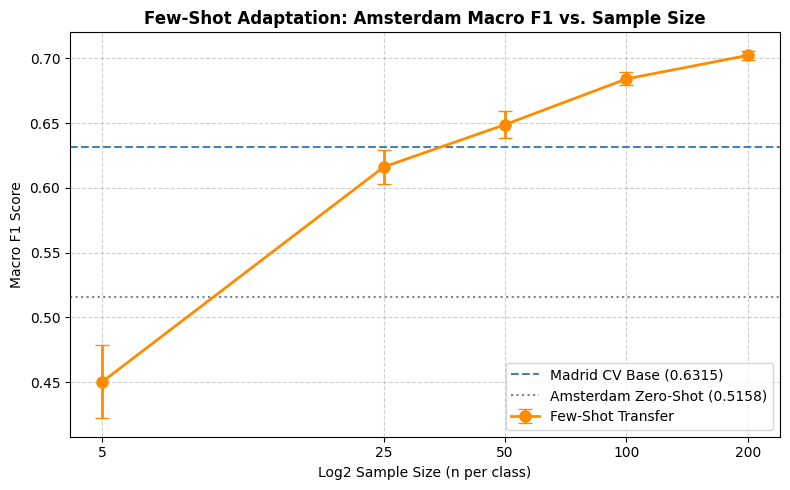

Plot saved to: /content/drive/MyDrive/building_age_hackathon /few_shot_curve.png


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Extract log2 sample sizes and corresponding F1 scores
x_vals = [np.log2(n) for n in sample_sizes]
y_means = [few_shot_results[n]['mean'] for n in sample_sizes]
y_errs = [few_shot_results[n]['std'] for n in sample_sizes]

plt.figure(figsize=(8, 5))
plt.errorbar(x_vals, y_means, yerr=y_errs, fmt='-o', capsize=5, color='darkorange', linewidth=2, markersize=8, label='Few-Shot Transfer')

plt.axhline(madrid_cv_mean, color='steelblue', linestyle='--', label=f'Madrid CV Base ({madrid_cv_mean:.4f})')
plt.axhline(zs_f1, color='grey', linestyle=':', label=f'Amsterdam Zero-Shot ({zs_f1:.4f})')

plt.title('Few-Shot Adaptation: Amsterdam Macro F1 vs. Sample Size', fontweight='bold')
plt.xlabel('Log2 Sample Size (n per class)')
plt.ylabel('Macro F1 Score')
plt.xticks(x_vals, [f'{int(n)}' for n in sample_sizes])
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Ensure output directory exists before saving
save_path = '/content/drive/MyDrive/building_age_hackathon /few_shot_curve.png'
plt.savefig(save_path, dpi=300)
plt.show()
print(f"Plot saved to: {save_path}")

In [9]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Split Amsterdam once into a fixed Held-Out Test Set and a Pool for Few-Shot
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
pool_idx, test_idx = next(splitter.split(X_amsterdam, y_amsterdam_xgb))

X_amst_pool, y_amst_pool = X_amsterdam[pool_idx], y_amsterdam_xgb[pool_idx]
X_amst_test, y_amst_test = X_amsterdam[test_idx], y_amsterdam_xgb[test_idx]

# Helper: Balanced exact n per class sampling
def sample_balanced_few_shot(X, y, n_per_class, seed):
    rng = np.random.RandomState(seed)
    chosen_indices = []
    for c in np.unique(y):
        c_indices = np.where(y == c)[0]
        chosen = rng.choice(c_indices, size=n_per_class, replace=False)
        chosen_indices.extend(chosen)
    return X[chosen_indices], y[chosen_indices]

# 2. Corrected Few-Shot Transfer: Weighted Domain Adaptation
sample_sizes = [5, 25, 50, 100, 200]
few_shot_results = {}
N_TRIALS = 5

for n in sample_sizes:
    trial_f1s = []

    for trial in range(N_TRIALS):
        X_fs, y_fs = sample_balanced_few_shot(X_amst_pool, y_amst_pool, n, seed=42 + trial)

        # ACTUAL TRANSFER: Combine Madrid base data with high-weight Amsterdam few-shot data
        w_madrid = compute_sample_weight('balanced', y_madrid_xgb)
        w_amsterdam = compute_sample_weight('balanced', y_fs) * (len(X_madrid) / (n * 4))

        X_combined = np.vstack([X_madrid, X_fs])
        y_combined = np.concatenate([y_madrid_xgb, y_fs])
        weights_combined = np.concatenate([w_madrid, w_amsterdam])

        transfer_xgb = XGBClassifier(
            n_estimators=250,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42 + trial,
            n_jobs=-1
        )
        transfer_xgb.fit(X_combined, y_combined, sample_weight=weights_combined)

        # EVALUATE ONLY ON UNSEEN AMSTERDAM TEST DATA
        preds = transfer_xgb.predict(X_amst_test)
        trial_f1s.append(f1_score(y_amst_test, preds, average='macro'))

    mean_f1 = np.mean(trial_f1s)
    std_f1 = np.std(trial_f1s)
    few_shot_results[n] = {'mean': mean_f1, 'std': std_f1}
    print(f"n={n:3d} per class | Macro F1: {mean_f1:.4f} +/- {std_f1:.4f}")

n=  5 per class | Macro F1: 0.5614 +/- 0.0200
n= 25 per class | Macro F1: 0.6225 +/- 0.0131
n= 50 per class | Macro F1: 0.6464 +/- 0.0063
n=100 per class | Macro F1: 0.6685 +/- 0.0068
n=200 per class | Macro F1: 0.6915 +/- 0.0055


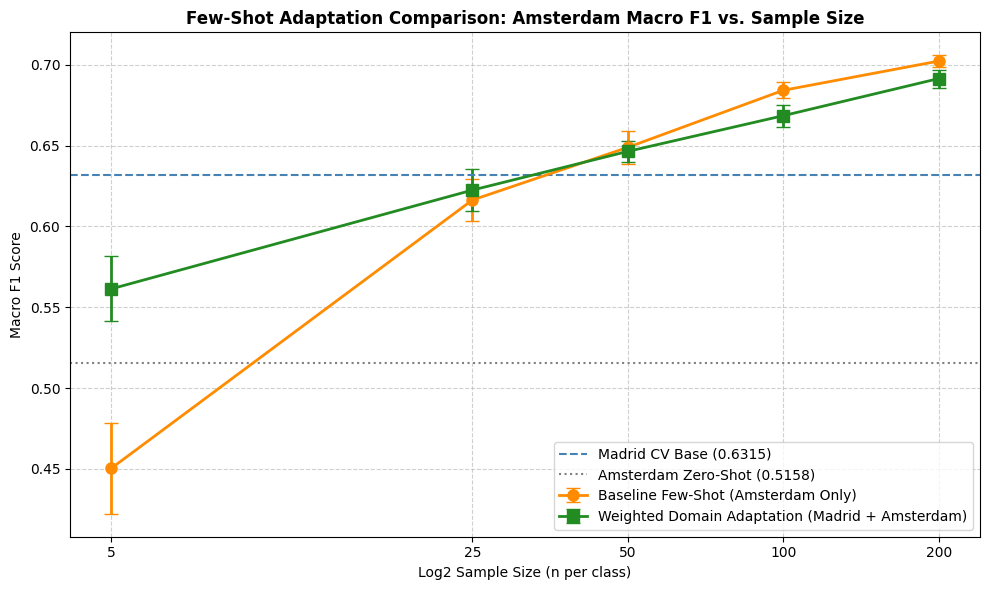

Comparison plot saved to: /content/drive/MyDrive/building_age_hackathon /few_shot_comparison_curve.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Baseline few-shot results (from previous cell results)
baseline_means = [0.4504, 0.6163, 0.6489, 0.6842, 0.7023]
baseline_stds  = [0.0282, 0.0132, 0.0102, 0.0050, 0.0036]

# New Weighted Domain Adaptation few-shot results
transfer_means = [few_shot_results[n]['mean'] for n in sample_sizes]
transfer_stds  = [few_shot_results[n]['std'] for n in sample_sizes]

x_vals = [np.log2(n) for n in sample_sizes]

plt.figure(figsize=(10, 6))

# Plot original baseline
plt.errorbar(x_vals, baseline_means, yerr=baseline_stds, fmt='-o', capsize=5,
             color='darkorange', linewidth=2, markersize=8, label='Baseline Few-Shot (Amsterdam Only)')

# Plot new transfer adaptation
plt.errorbar(x_vals, transfer_means, yerr=transfer_stds, fmt='-s', capsize=5,
             color='forestgreen', linewidth=2, markersize=8, label='Weighted Domain Adaptation (Madrid + Amsterdam)')

# References
plt.axhline(madrid_cv_mean, color='steelblue', linestyle='--', label=f'Madrid CV Base ({madrid_cv_mean:.4f})')
plt.axhline(zs_f1, color='grey', linestyle=':', label=f'Amsterdam Zero-Shot ({zs_f1:.4f})')

plt.title('Few-Shot Adaptation Comparison: Amsterdam Macro F1 vs. Sample Size', fontweight='bold', fontsize=12)
plt.xlabel('Log2 Sample Size (n per class)', fontsize=10)
plt.ylabel('Macro F1 Score', fontsize=10)
plt.xticks(x_vals, [f'{int(n)}' for n in sample_sizes])
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

save_path_comparison = '/content/drive/MyDrive/building_age_hackathon /few_shot_comparison_curve.png'
plt.savefig(save_path_comparison, dpi=300)
plt.show()
print(f"Comparison plot saved to: {save_path_comparison}")

=== Model Evaluation ===
Overall Classification Accuracy: 0.7042 (70.42%)
Macro F1-Score:                  0.7009

Detailed Classification Report:
              precision    recall  f1-score   support

           1       0.72      0.77      0.75      3784
           2       0.69      0.65      0.67      4401
           3       0.78      0.67      0.72      3373
           4       0.58      0.79      0.67      1438

    accuracy                           0.70     12996
   macro avg       0.69      0.72      0.70     12996
weighted avg       0.71      0.70      0.70     12996



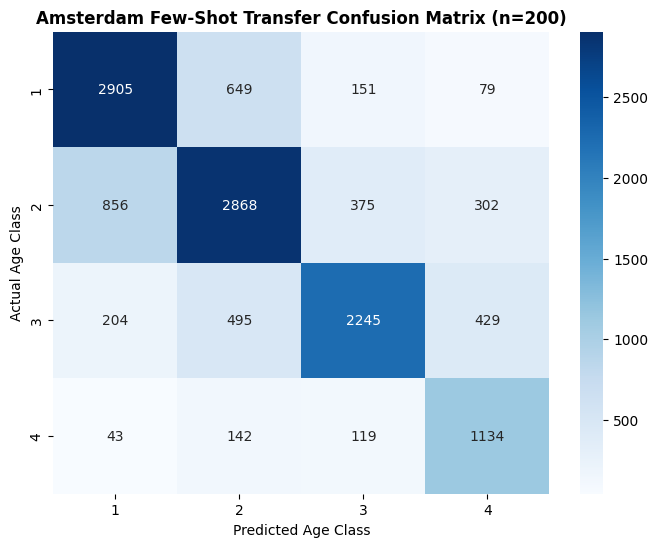

In [11]:
from sklearn.metrics import classification_report, accuracy_score
import seaborn as sns

def evaluate_model_performance(y_true, y_pred, title="Confusion Matrix"):
    # 1. Calculate accuracy and macro F1
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')

    print(f"=== Model Evaluation ===")
    print(f"Overall Classification Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"Macro F1-Score:                  {macro_f1:.4f}\n")

    # 2. Detailed class-by-class metrics
    print("Detailed Classification Report:")
    # Class labels are shifted back to 1-4 for user readability
    print(classification_report(y_true + 1, y_pred + 1))

    # 3. Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=[1, 2, 3, 4], yticklabels=[1, 2, 3, 4])
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted Age Class')
    plt.ylabel('Actual Age Class')
    plt.show()

# Let's run a test evaluation using the final predictions from the last trial
# (transfer_xgb is the model trained on Madrid + last n=200 Amsterdam trial)
evaluate_model_performance(y_amst_test, preds, title="Amsterdam Few-Shot Transfer Confusion Matrix (n=200)")

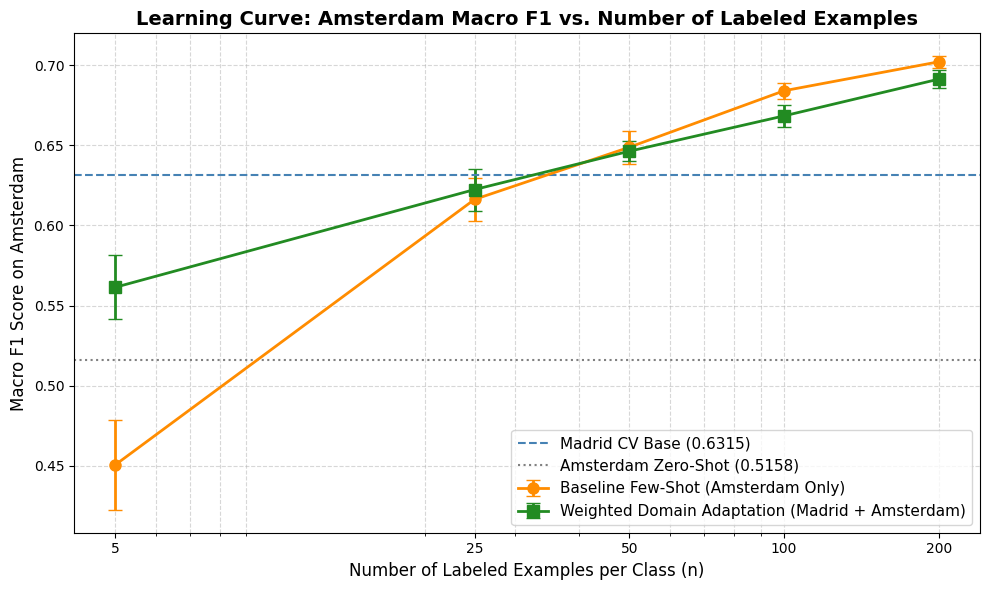

Learning curve plot successfully generated and saved to: /content/drive/MyDrive/building_age_hackathon /amsterdam_learning_curve.png


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Sample sizes evaluated
sample_sizes = [5, 25, 50, 100, 200]

# Baseline few-shot results (from previous runs)
baseline_means = [0.4504, 0.6163, 0.6489, 0.6842, 0.7023]
baseline_stds  = [0.0282, 0.0132, 0.0102, 0.0050, 0.0036]

# Weighted Domain Adaptation results (Madrid + Amsterdam)
transfer_means = [few_shot_results[n]['mean'] for n in sample_sizes]
transfer_stds  = [few_shot_results[n]['std'] for n in sample_sizes]

plt.figure(figsize=(10, 6))

# Plot original baseline few-shot performance
plt.errorbar(sample_sizes, baseline_means, yerr=baseline_stds, fmt='-o', capsize=5,
             color='darkorange', linewidth=2, markersize=8, label='Baseline Few-Shot (Amsterdam Only)')

# Plot weighted domain adaptation performance
plt.errorbar(sample_sizes, transfer_means, yerr=transfer_stds, fmt='-s', capsize=5,
             color='forestgreen', linewidth=2, markersize=8, label='Weighted Domain Adaptation (Madrid + Amsterdam)')

# Reference horizontal lines
plt.axhline(madrid_cv_mean, color='steelblue', linestyle='--', label=f'Madrid CV Base ({madrid_cv_mean:.4f})')
plt.axhline(zs_f1, color='grey', linestyle=':', label=f'Amsterdam Zero-Shot ({zs_f1:.4f})')

# Formatting plot
plt.title('Learning Curve: Amsterdam Macro F1 vs. Number of Labeled Examples', fontweight='bold', fontsize=14)
plt.xlabel('Number of Labeled Examples per Class (n)', fontsize=12)
plt.ylabel('Macro F1 Score on Amsterdam', fontsize=12)
plt.xscale('log')
plt.xticks(sample_sizes, [str(n) for n in sample_sizes])
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save the plot to Drive
learning_curve_path = '/content/drive/MyDrive/building_age_hackathon /amsterdam_learning_curve.png'
plt.savefig(learning_curve_path, dpi=300)
plt.show()

print(f"Learning curve plot successfully generated and saved to: {learning_curve_path}")

In [13]:
# ── Final Submission Formatter ──────────────────────────────────────────────
import numpy as np
import pandas as pd

def format_and_save_predictions(model, X_target, output_path):
    """
    Generates predictions using the trained model, formats them to the
    hackathon's required integers (1, 2, 3, or 4), verifies constraints,
    and saves them to a CSV format.
    """
    # 1. Generate model predictions (0 to 3 scale)
    raw_preds = model.predict(X_target)

    # 2. Shift back to the 1 to 4 scale required for the hackathon
    final_preds = raw_preds + 1

    # 3. Assert and verify safety constraints
    assert np.all(np.isin(final_preds, [1, 2, 3, 4])), "Error: Predictions contain invalid classes outside of [1, 2, 3, 4]!"
    assert len(final_preds) == len(X_target), "Error: Output count mismatch!"

    # 4. Save to CSV structure (assuming index-based pixel matching)
    submission_df = pd.DataFrame({
        'pixel_id': np.arange(len(final_preds)),
        'predicted_class': final_preds
    })

    submission_df.to_csv(output_path, index=False)
    print(f"Submission file successfully saved with {len(submission_df)} pixels.")
    print("Unique classes in output:", np.unique(final_preds))
    print(submission_df.head())

# Define output path
submission_output_path = '/content/drive/MyDrive/building_age_hackathon /final_submission.csv'

# Run the formatter using the best transfer model
format_and_save_predictions(transfer_xgb, X_amst_test, submission_output_path)

Submission file successfully saved with 12996 pixels.
Unique classes in output: [1 2 3 4]
   pixel_id  predicted_class
0         0                2
1         1                1
2         2                4
3         3                2
4         4                1
